In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Setup successful!")
print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

Setup successful!
TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Load the CIFAR-10 dataset
from tensorflow.keras.datasets import cifar10

(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print("Dataset loaded successfully!")
print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing images shape:", x_test.shape)
print("Testing labels shape:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1987s 12us/step
Dataset loaded successfully!
Training images shape: (50000, 32, 32, 3)
Training labels shape: (50000, 1)
Testing images shape: (10000, 32, 32, 3)
Testing labels shape: (10000, 1)


All dataset checks passed!
Number of classes: 10
Pixel value range: 0 to 255


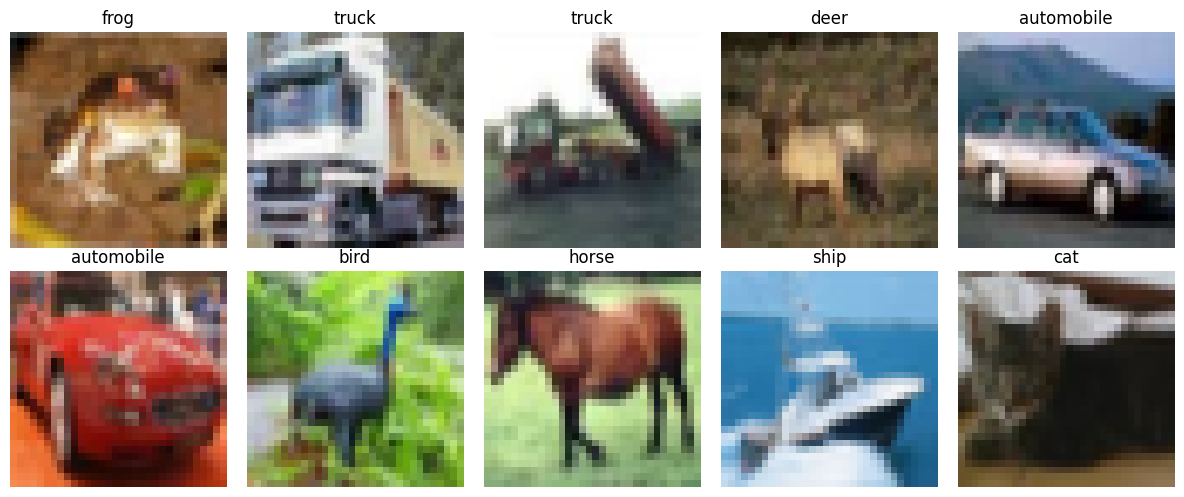

In [ ]:
# Define the 10 class names
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Verify the dataset
assert x_train.shape == (50000, 32, 32, 3)
assert x_test.shape == (10000, 32, 32, 3)
assert len(class_names) == 10
assert y_train.min() >= 0 and y_train.max() <= 9

print("All dataset checks passed!")
print("Number of classes:", len(class_names))
print("Pixel value range:", x_train.min(), "to", x_train.max())

# Display 10 sample images
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[int(y_train[i][0])])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# Convert labels from shape (N, 1) to (N,)
y_train_flat = y_train.reshape(-1)

# Split training data into training and validation sets
x_train_split, x_val, y_train_split, y_val = train_test_split(
    x_train,
    y_train_flat,
    test_size=0.10,
    random_state=42,
    stratify=y_train_flat
)

print("Training set:", x_train_split.shape, y_train_split.shape)
print("Validation set:", x_val.shape, y_val.shape)
print("Test set:", x_test.shape, y_test.shape)

assert len(x_train_split) == 45000
assert len(x_val) == 5000
assert len(x_test) == 10000

print("Data split checks passed!")

Training set: (45000, 32, 32, 3) (45000,)
Validation set: (5000, 32, 32, 3) (5000,)
Test set: (10000, 32, 32, 3) (10000, 1)
Data split checks passed!


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

# Normalize pixel values
normalization = layers.Rescaling(1.0 / 255.0)

# Data augmentation: applied during training only
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
], name="data_augmentation")

# Test normalization on a sample image
sample_normalized = normalization(x_train_split[:1])

print("Original pixel range:",
      x_train_split[:1].min(), "to", x_train_split[:1].max())

print("Normalized pixel range:",
      float(tf.reduce_min(sample_normalized)),
      "to",
      float(tf.reduce_max(sample_normalized)))

print("Augmentation layers created successfully!")

Original pixel range: 0 to 253
Normalized pixel range: 0.0 to 0.9921569228172302
Augmentation layers created successfully!


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 128

def prepare_image(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.cast(label, tf.int32)

# Training dataset
train_ds = (
    tf.data.Dataset.from_tensor_slices((x_train_split, y_train_split))
    .shuffle(10000, seed=42, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .map(prepare_image, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

# Validation dataset
val_ds = (
    tf.data.Dataset.from_tensor_slices((x_val, y_val))
    .batch(BATCH_SIZE)
    .map(prepare_image, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

# Test dataset
test_ds = (
    tf.data.Dataset.from_tensor_slices((x_test, y_test.reshape(-1)))
    .batch(BATCH_SIZE)
    .map(prepare_image, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

# Verify one batch
images, labels = next(iter(train_ds))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Batch pixel range:",
      float(tf.reduce_min(images)),
      "to",
      float(tf.reduce_max(images)))

assert images.shape[1:] == (32, 32, 3)
assert labels.shape[0] == images.shape[0]
assert float(tf.reduce_min(images)) >= 0.0
assert float(tf.reduce_max(images)) <= 1.0

print("Data pipeline checks passed!")

Batch image shape: (128, 32, 32, 3)
Batch label shape: (128,)
Batch pixel range: 0.0 to 1.0
Data pipeline checks passed!


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

# Build CNN from scratch
model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),

    # Augmentation runs during training only
    data_augmentation,

    # Convolution block 1
    layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.20),

    # Convolution block 2
    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Convolution block 3
    layers.Conv2D(128, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.30),

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.40),
    layers.Dense(10)  # Raw logits for 10 classes
], name="cifar10_cnn")

# Compile the model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=["accuracy"]
)

print("CNN model created successfully!")
model.summary()

CNN model created successfully!


Model: "cifar10_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 158,186 (617.91 KB)

 Trainable params: 157,546 (615.41 KB)

 Non-trainable params: 640 (2.50 KB)

In [ ]:
# Run one batch through the model
sample_images, sample_labels = next(iter(train_ds))

sample_logits = model(sample_images, training=False)

print("Input shape:", sample_images.shape)
print("Output shape:", sample_logits.shape)
print("Total parameters:", model.count_params())

# Basic architecture checks
assert sample_logits.shape == (sample_images.shape[0], 10)
assert model.count_params() > 0

# Check for invalid numerical values
tf.debugging.assert_all_finite(
    sample_logits,
    "Model output contains NaN or infinity!"
)

print("Model verification passed!")

Input shape: (128, 32, 32, 3)
Output shape: (128, 10)
Total parameters: 158186
Model verification passed!


In [ ]:
import os
from tensorflow import keras

# Create folders for saved models and plots
os.makedirs("outputs/checkpoints", exist_ok=True)
os.makedirs("outputs/plots", exist_ok=True)

checkpoint_path = "outputs/checkpoints/best_cifar10.keras"

# Callback 1: Save the best model based on validation loss
checkpoint_cb = keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Callback 2: Stop if validation loss stops improving
early_stopping_cb = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Callback 3: Reduce learning rate when progress plateaus
reduce_lr_cb = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

print("Training callbacks created successfully!")

Training callbacks created successfully!


In [ ]:
class TrainingLogger(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}

        learning_rate = float(
            keras.backend.get_value(
                self.model.optimizer.learning_rate
            )
        )

        print(
            f"Epoch {epoch + 1}: "
            f"train_loss={logs.get('loss', 0):.4f}, "
            f"train_acc={logs.get('accuracy', 0):.4f}, "
            f"val_loss={logs.get('val_loss', 0):.4f}, "
            f"val_acc={logs.get('val_accuracy', 0):.4f}, "
            f"lr={learning_rate:.6f}"
        )

logger_cb = TrainingLogger()

print("Custom training logger created successfully!")

Custom training logger created successfully!


In [ ]:
EPOCHS = 20

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[
        checkpoint_cb,
        early_stopping_cb,
        reduce_lr_cb,
        logger_cb
    ],
    verbose=1
)

print("Training completed!")
print("Best validation accuracy:",
      max(history.history["val_accuracy"]))
print("Best validation loss:",
      min(history.history["val_loss"]))

Epoch 1/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.3248 - loss: 1.8379
Epoch 1: val_loss improved from None to 2.28291, saving model to outputs/checkpoints/best_cifar10.keras

Epoch 1: finished saving model to outputs/checkpoints/best_cifar10.keras
Epoch 1: train_loss=1.6459, train_acc=0.3915, val_loss=2.2829, val_acc=0.2884, lr=0.001000
352/352 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.3915 - loss: 1.6459 - val_accuracy: 0.2884 - val_loss: 2.2829 - learning_rate: 0.0010
Epoch 2/20
350/352 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.4990 - loss: 1.3765
Epoch 2: val_loss improved from 2.28291 to 1.23454, saving model to outputs/checkpoints/best_cifar10.keras

Epoch 2: finished saving model to outputs/checkpoints/best_cifar10.keras
Epoch 2: train_loss=1.3314, train_acc=0.5153, val_loss=1.2345, val_acc=0.5514, lr=0.001000
352/352 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.5153 - loss: 1.3314 - val_accuracy: 0.5514 - val_loss: 1.2345 - learning_rate: 0.0010


In [ ]:
import os
import tensorflow as tf

assert os.path.exists(checkpoint_path), (
    "Checkpoint not found. Check the training output."
)

best_model = tf.keras.models.load_model(checkpoint_path)

print("Saved model loaded successfully!")
print("Saved model name:", best_model.name)
print("Model output shape:", best_model.output_shape)
print("Checkpoint size (MB):",
      round(os.path.getsize(checkpoint_path) / (1024 * 1024), 2))

assert best_model.output_shape == (None, 10)

print("Checkpoint verification passed!")

Saved model loaded successfully!
Saved model name: cifar10_cnn
Model output shape: (None, 10)
Checkpoint size (MB): 1.91
Checkpoint verification passed!


In [ ]:
# Evaluate the saved best model on unseen test data
test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print("\n--- Final Test Results ---")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.7523 - loss: 0.6930

--- Final Test Results ---
Test Loss: 0.6930
Test Accuracy: 75.23%


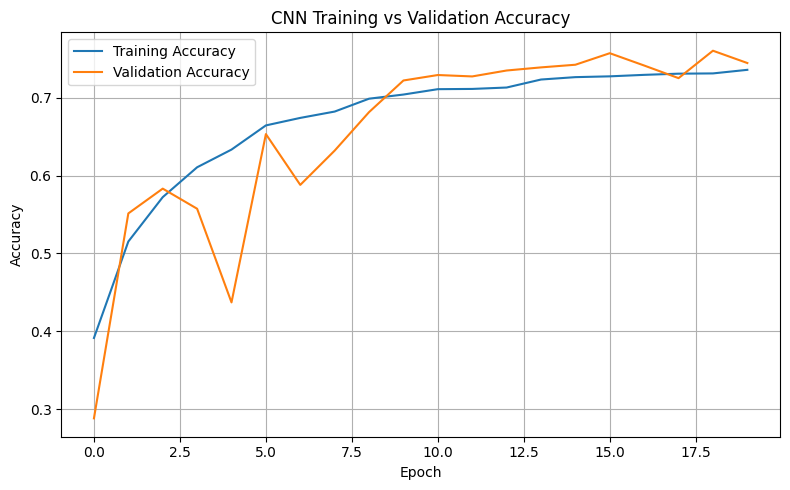

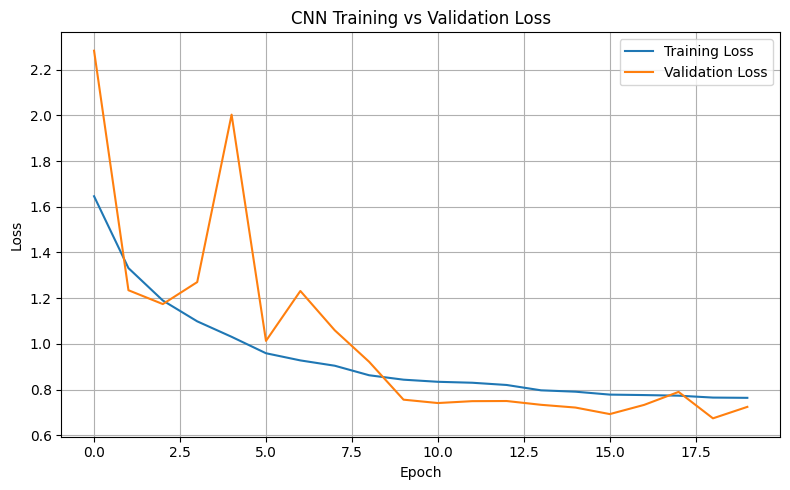

Training plots saved successfully!


In [ ]:
import matplotlib.pyplot as plt

os.makedirs("outputs/plots", exist_ok=True)

# Accuracy plot
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("outputs/plots/accuracy.png", dpi=150)
plt.show()

# Loss plot
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("outputs/plots/loss.png", dpi=150)
plt.show()

print("Training plots saved successfully!")

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Predict raw logits on the test set
logits = best_model.predict(test_ds, verbose=1)

# Convert logits to class predictions
y_pred = np.argmax(logits, axis=1)
y_true = y_test.reshape(-1)

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(10),
    target_names=class_names,
    digits=4,
    zero_division=0
))

79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
              precision    recall  f1-score   support

    airplane     0.8398    0.6920    0.7588      1000
  automobile     0.9158    0.8370    0.8746      1000
        bird     0.7114    0.5720    0.6341      1000
         cat     0.5974    0.5460    0.5705      1000
        deer     0.7226    0.6980    0.7101      1000
         dog     0.7182    0.6320    0.6723      1000
        frog     0.6518    0.9080    0.7589      1000
       horse     0.8254    0.7990    0.8120      1000
        ship     0.8526    0.8910    0.8714      1000
       truck     0.7337    0.9480    0.8272      1000

    accuracy                         0.7523     10000
   macro avg     0.7569    0.7523    0.7490     10000
weighted avg     0.7569    0.7523    0.7490     10000



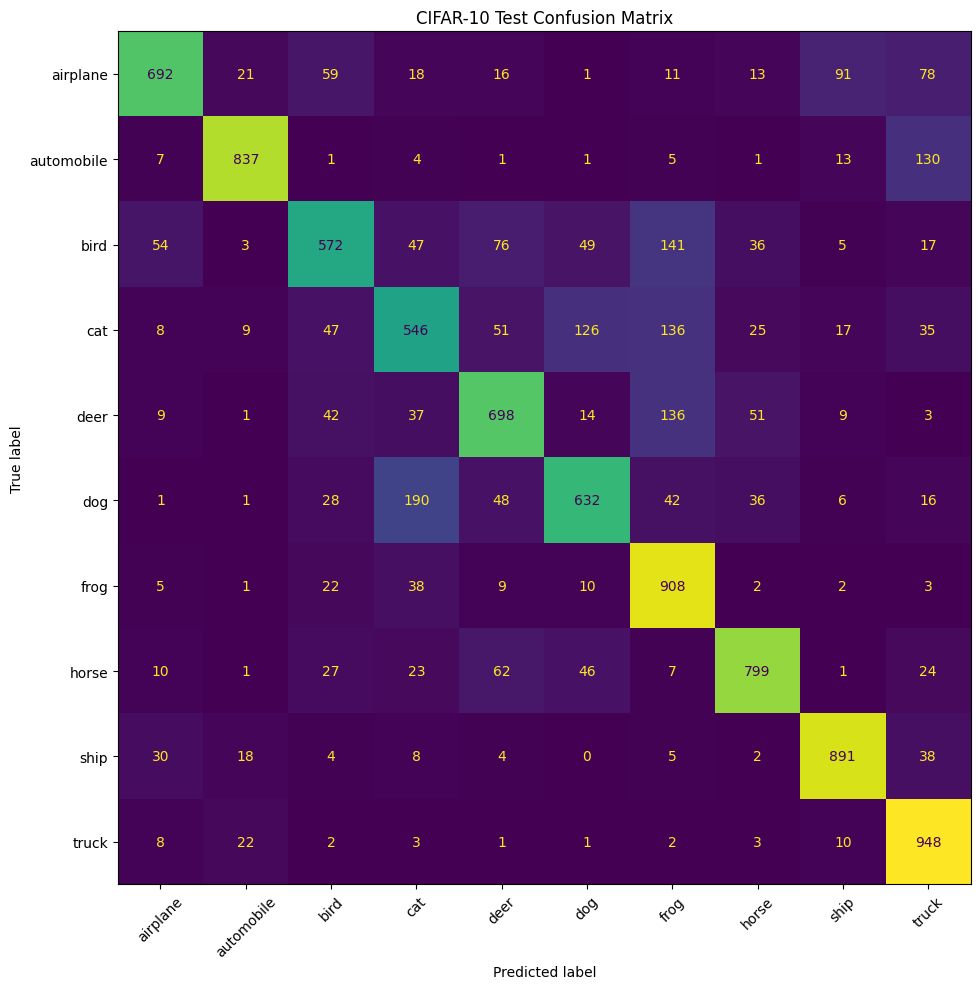

Confusion matrix saved successfully!


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(10, 10))
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
display.plot(ax=ax, xticks_rotation=45, colorbar=False)
ax.set_title("CIFAR-10 Test Confusion Matrix")
plt.tight_layout()
plt.savefig("outputs/plots/confusion_matrix.png", dpi=150)
plt.show()

print("Confusion matrix saved successfully!")

Misclassified images: 2477
Total test images: 10000


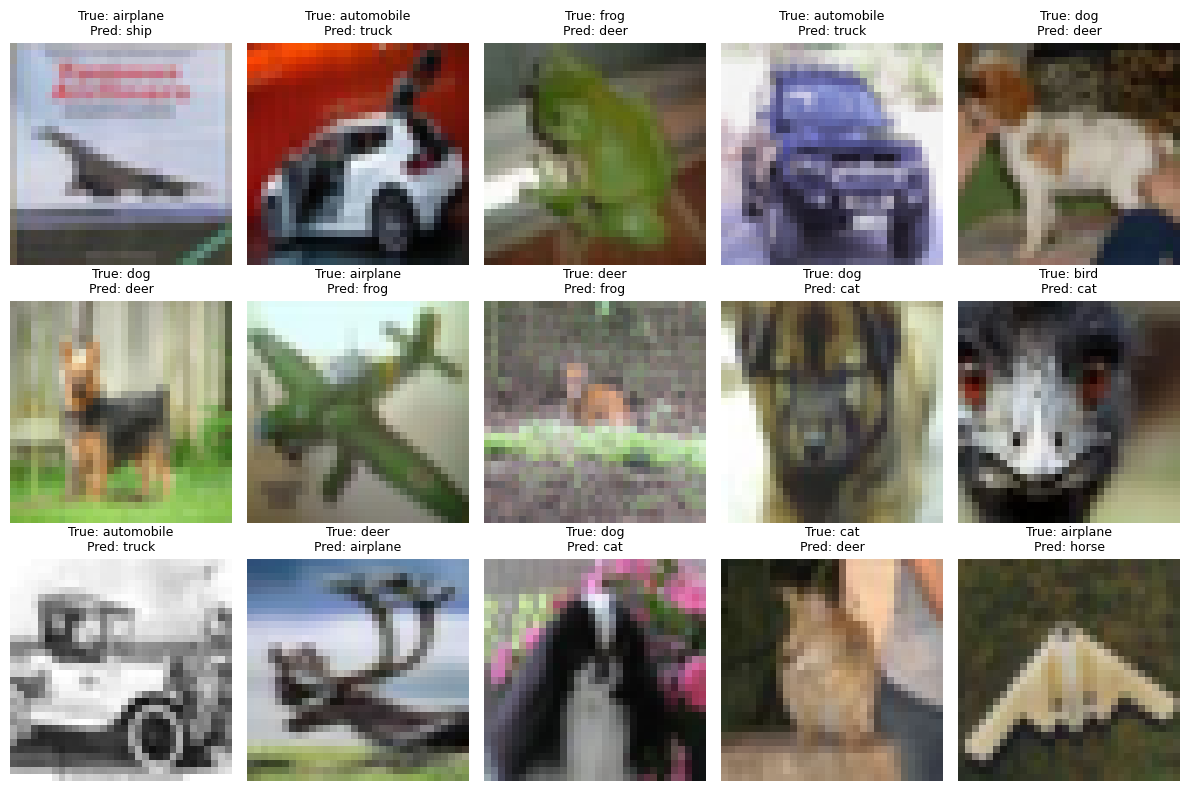

In [ ]:
wrong_indices = np.where(y_pred != y_true)[0]

print("Misclassified images:", len(wrong_indices))
print("Total test images:", len(y_true))

if len(wrong_indices) > 0:
    sample_indices = wrong_indices[:15]

    plt.figure(figsize=(12, 8))
    for plot_idx, image_idx in enumerate(sample_indices):
        plt.subplot(3, 5, plot_idx + 1)
        plt.imshow(x_test[image_idx])
        plt.title(
            f"True: {class_names[y_true[image_idx]]}\n"
            f"Pred: {class_names[y_pred[image_idx]]}",
            fontsize=9
        )
        plt.axis("off")

    plt.tight_layout()
    plt.savefig("outputs/plots/misclassified.png", dpi=150)
    plt.show()
else:
    print("No misclassified images found.")

In [ ]:
# Create a fresh model with the same CNN architecture
tuned_model = keras.models.clone_model(model)

# Compile with a lower learning rate
tuned_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0003),
    loss=keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=["accuracy"]
)

# Save the tuned model separately
tuned_checkpoint = "outputs/checkpoints/tuned_cifar10.keras"

tuned_callbacks = [
    keras.callbacks.ModelCheckpoint(
        tuned_checkpoint,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),
    TrainingLogger()
]

print("Baseline learning rate: 0.001")
print("Tuned learning rate: 0.0003")
print("Starting tuned experiment...")

tuned_history = tuned_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=tuned_callbacks,
    verbose=1
)

print("Tuned experiment completed!")
print("Best tuned validation accuracy:",
      max(tuned_history.history["val_accuracy"]))
print("Best tuned validation loss:",
      min(tuned_history.history["val_loss"]))

Baseline learning rate: 0.001
Tuned learning rate: 0.0003
Starting tuned experiment...
Epoch 1/20
350/352 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.2624 - loss: 2.0139
Epoch 1: val_loss improved from None to 2.81034, saving model to outputs/checkpoints/tuned_cifar10.keras

Epoch 1: finished saving model to outputs/checkpoints/tuned_cifar10.keras
Epoch 1: train_loss=1.8246, train_acc=0.3252, val_loss=2.8103, val_acc=0.1144, lr=0.000300
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 33ms/step - accuracy: 0.3252 - loss: 1.8246 - val_accuracy: 0.1144 - val_loss: 2.8103 - learning_rate: 3.0000e-04
Epoch 2/20
351/352 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.4301 - loss: 1.5608
Epoch 2: val_loss improved from 2.81034 to 1.45679, saving model to outputs/checkpoints/tuned_cifar10.keras

Epoch 2: finished saving model to outputs/checkpoints/tuned_cifar10.keras
Epoch 2: train_loss=1.5190, train_acc=0.4458, val_loss=1.4568, val_acc=0.4684, lr=0.000300
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - ac

In [ ]:
# Load the best tuned model
tuned_model = keras.models.load_model(tuned_checkpoint)

# Compare validation performance first
baseline_val_acc = max(history.history["val_accuracy"])
tuned_val_acc = max(tuned_history.history["val_accuracy"])

print(f"Baseline validation accuracy: {baseline_val_acc * 100:.2f}%")
print(f"Tuned validation accuracy:    {tuned_val_acc * 100:.2f}%")
print(f"Validation change:             {(tuned_val_acc - baseline_val_acc) * 100:+.2f} percentage points")

Baseline validation accuracy: 76.02%
Tuned validation accuracy:    66.94%
Validation change:             -9.08 percentage points


In [ ]:
# Evaluate the tuned model
tuned_test_loss, tuned_test_acc = tuned_model.evaluate(
    test_ds, verbose=1
)

# Baseline test metrics already measured in Step 6
baseline_test_acc = test_accuracy
baseline_test_loss = test_loss

print("\n--- Baseline vs Tuned Model ---")
print(f"{'Metric':<20}{'Baseline':>12}{'Tuned':>12}")
print("-" * 44)
print(f"{'Test accuracy':<20}{baseline_test_acc * 100:>11.2f}%{tuned_test_acc * 100:>11.2f}%")
print(f"{'Test loss':<20}{baseline_test_loss:>12.4f}{tuned_test_loss:>12.4f}")
print(f"{'Accuracy change':<20}{'':>12}{(tuned_test_acc - baseline_test_acc) * 100:>+11.2f} pp")

79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.6725 - loss: 0.9286

--- Baseline vs Tuned Model ---
Metric                  Baseline       Tuned
--------------------------------------------
Test accuracy             75.23%      67.25%
Test loss                 0.6930      0.9286
Accuracy change                       -7.98 pp


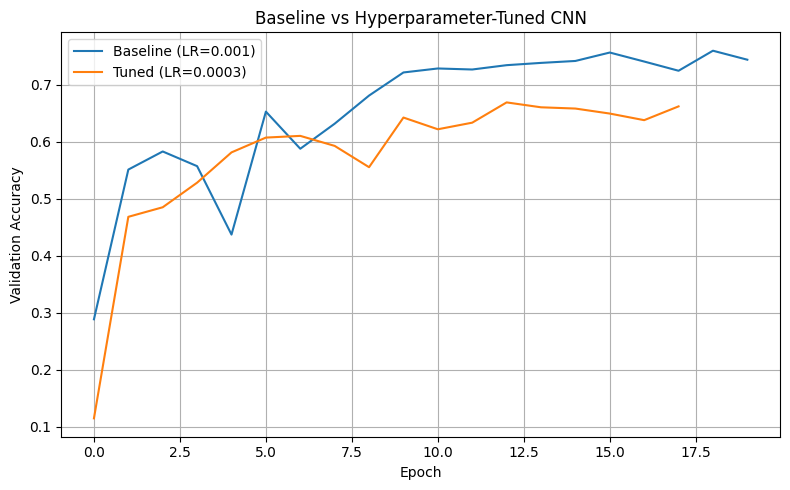

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["val_accuracy"],
    label="Baseline (LR=0.001)"
)
plt.plot(
    tuned_history.history["val_accuracy"],
    label="Tuned (LR=0.0003)"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Baseline vs Hyperparameter-Tuned CNN")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("outputs/plots/baseline_vs_tuned.png", dpi=150)
plt.show()

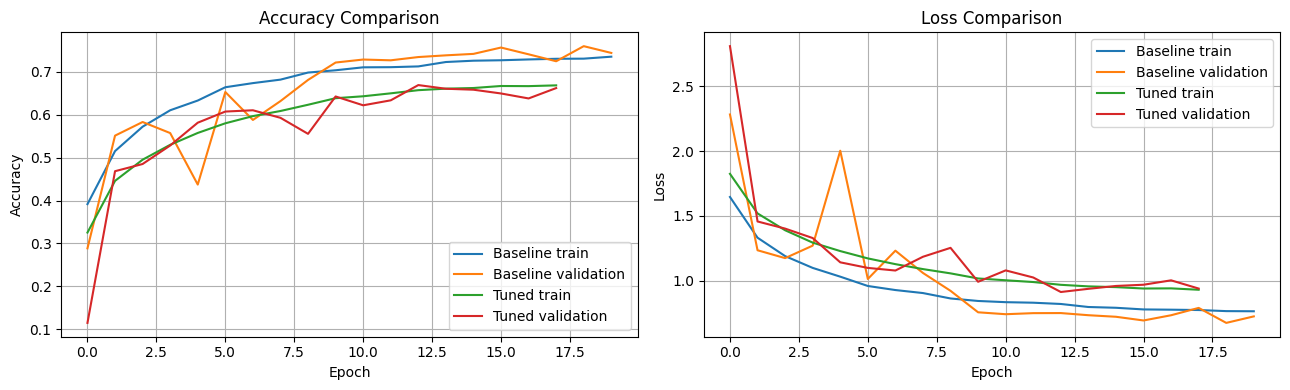

Baseline best epoch: 19
Tuned best epoch: 13


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Training accuracy
axes[0].plot(history.history["accuracy"], label="Baseline train")
axes[0].plot(history.history["val_accuracy"], label="Baseline validation")
axes[0].plot(tuned_history.history["accuracy"], label="Tuned train")
axes[0].plot(tuned_history.history["val_accuracy"], label="Tuned validation")
axes[0].set_title("Accuracy Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Training loss
axes[1].plot(history.history["loss"], label="Baseline train")
axes[1].plot(history.history["val_loss"], label="Baseline validation")
axes[1].plot(tuned_history.history["loss"], label="Tuned train")
axes[1].plot(tuned_history.history["val_loss"], label="Tuned validation")
axes[1].set_title("Loss Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("outputs/plots/tuning_diagnostics.png", dpi=150)
plt.show()

print("Baseline best epoch:",
      1 + history.history["val_accuracy"].index(
          max(history.history["val_accuracy"])
      ))

print("Tuned best epoch:",
      1 + tuned_history.history["val_accuracy"].index(
          max(tuned_history.history["val_accuracy"])
      ))

In [ ]:
# Experiment 3: Original learning rate, longer training
final_candidate = keras.models.clone_model(model)

final_candidate.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=["accuracy"]
)

candidate_path = "outputs/checkpoints/experiment3_best.keras"

candidate_callbacks = [
    keras.callbacks.ModelCheckpoint(
        candidate_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),
    TrainingLogger()
]

candidate_history = final_candidate.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=candidate_callbacks,
    verbose=1
)

print("Experiment 3 completed!")
print("Best validation accuracy:",
      max(candidate_history.history["val_accuracy"]))
print("Best validation loss:",
      min(candidate_history.history["val_loss"]))

Epoch 1/30
350/352 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.3097 - loss: 1.8769
Epoch 1: val_loss improved from None to 2.20787, saving model to outputs/checkpoints/experiment3_best.keras

Epoch 1: finished saving model to outputs/checkpoints/experiment3_best.keras
Epoch 1: train_loss=1.6567, train_acc=0.3864, val_loss=2.2079, val_acc=0.2460, lr=0.001000
352/352 ━━━━━━━━━━━━━━━━━━━━ 17s 30ms/step - accuracy: 0.3864 - loss: 1.6567 - val_accuracy: 0.2460 - val_loss: 2.2079 - learning_rate: 0.0010
Epoch 2/30
351/352 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.5077 - loss: 1.3431
Epoch 2: val_loss improved from 2.20787 to 1.36299, saving model to outputs/checkpoints/experiment3_best.keras

Epoch 2: finished saving model to outputs/checkpoints/experiment3_best.keras
Epoch 2: train_loss=1.3029, train_acc=0.5274, val_loss=1.3630, val_acc=0.5046, lr=0.001000
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.5274 - loss: 1.3029 - val_accuracy: 0.5046 - val_loss: 1.3630 - learn

In [ ]:
baseline_val_acc = max(history.history["val_accuracy"])
tuned_val_acc = max(tuned_history.history["val_accuracy"])
candidate_val_acc = max(candidate_history.history["val_accuracy"])

validation_results = {
    "Baseline (LR=0.001, 20 epochs)": baseline_val_acc,
    "Tuned (LR=0.0003, 20 epochs)": tuned_val_acc,
    "Experiment 3 (LR=0.001, up to 30 epochs)": candidate_val_acc
}

for name, accuracy in validation_results.items():
    print(f"{name}: {accuracy * 100:.2f}%")

best_experiment = max(validation_results, key=validation_results.get)
print("\nBest experiment by validation accuracy:", best_experiment)

Baseline (LR=0.001, 20 epochs): 76.02%
Tuned (LR=0.0003, 20 epochs): 66.94%
Experiment 3 (LR=0.001, up to 30 epochs): 79.56%

Best experiment by validation accuracy: Experiment 3 (LR=0.001, up to 30 epochs)


In [ ]:
candidate_model = keras.models.load_model(candidate_path)

candidate_test_loss, candidate_test_acc = candidate_model.evaluate(
    test_ds,
    verbose=1
)

print("\n--- Test Comparison ---")
print(f"Baseline test accuracy:   {test_accuracy * 100:.2f}%")
print(f"Experiment 3 test accuracy: {candidate_test_acc * 100:.2f}%")
print(f"Change: {(candidate_test_acc - test_accuracy) * 100:+.2f} percentage points")
print(f"Experiment 3 test loss: {candidate_test_loss:.4f}")

79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7857 - loss: 0.6218

--- Test Comparison ---
Baseline test accuracy:   75.23%
Experiment 3 test accuracy: 78.57%
Change: +3.34 percentage points
Experiment 3 test loss: 0.6218


In [ ]:
import os
import json
import shutil
import zipfile
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from google.colab import files

# Create final output folders
os.makedirs("outputs/checkpoints", exist_ok=True)
os.makedirs("outputs/plots", exist_ok=True)

# Save the selected candidate model
final_model_path = "outputs/checkpoints/final_cifar10_model.keras"
candidate_model.save(final_model_path)

# Generate predictions from the final model
final_logits = candidate_model.predict(test_ds, verbose=1)
final_predictions = np.argmax(final_logits, axis=1)
true_labels = y_test.reshape(-1)

# Calculate final classification metrics
report = classification_report(
    true_labels,
    final_predictions,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

# Save baseline vs improved experiment results
results = {
    "dataset": "CIFAR-10",
    "model": "CNN from scratch",
    "baseline_learning_rate": 0.001,
    "baseline_max_epochs": 20,
    "baseline_test_accuracy": float(test_accuracy),
    "baseline_test_loss": float(test_loss),
    "tuned_learning_rate": 0.0003,
    "tuned_validation_accuracy": float(
        max(tuned_history.history["val_accuracy"])
    ),
    "improved_learning_rate": 0.001,
    "improved_max_epochs": 30,
    "improved_test_accuracy": float(candidate_test_acc),
    "improved_test_loss": float(candidate_test_loss),
    "accuracy_change_percentage_points": float(
        (candidate_test_acc - test_accuracy) * 100
    ),
    "improved_classification_report": report
}

with open("outputs/results.json", "w") as f:
    json.dump(results, f, indent=2)

# Save accuracy and loss curves for the final experiment
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    candidate_history.history["accuracy"],
    label="Training accuracy"
)
axes[0].plot(
    candidate_history.history["val_accuracy"],
    label="Validation accuracy"
)
axes[0].set_title("Final Experiment: Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    candidate_history.history["loss"],
    label="Training loss"
)
axes[1].plot(
    candidate_history.history["val_loss"],
    label="Validation loss"
)
axes[1].set_title("Final Experiment: Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("outputs/plots/final_training_curves.png", dpi=150)
plt.close()

# Create the README
readme = f"""# CIFAR-10 Image Classification Using CNN

## Overview
This project implements a convolutional neural network from scratch
using TensorFlow/Keras to classify CIFAR-10 images into 10 classes.

## Dataset
- 45,000 training images
- 5,000 validation images
- 10,000 test images
- Image dimensions: 32 x 32 x 3
- Number of classes: 10

## Model
- Convolutional layers
- Batch Normalization
- ReLU activations
- Max Pooling
- Dropout
- Global Average Pooling
- Dense classification layer

Training uses image augmentation, Adam, Early Stopping,
ReduceLROnPlateau, ModelCheckpoint, and a custom training logger.

## Results

| Metric | Baseline | Improved experiment |
|---|---:|---:|
| Test accuracy | {test_accuracy * 100:.2f}% | {candidate_test_acc * 100:.2f}% |
| Test loss | {test_loss:.4f} | {candidate_test_loss:.4f} |

Accuracy change: {(candidate_test_acc - test_accuracy) * 100:+.2f}
percentage points.

The improved experiment used a learning rate of 0.001 and a maximum
of 30 epochs, compared with 20 epochs for the baseline.
Early stopping may terminate training before the maximum.

A separate experiment using a learning rate of 0.0003 did not
improve validation accuracy in this run.

## Project Files
- checkpoints/final_cifar10_model.keras: final saved model
- results.json: metrics and classification report
- plots/: training curves and experiment plots

## How to Run
Open CIFAR10_Image_Classification.ipynb in Google Colab and run
the notebook cells in order. The dataset is loaded through Keras.

## Limitations
Results depend on the training configuration and random seeds.
The test set is intended for final evaluation rather than repeated
hyperparameter selection.
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme)

# Package project artifacts
zip_path = "cifar10_assignment_submission.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    zf.write("README.md")
    for root, dirs, filenames in os.walk("outputs"):
        for filename in filenames:
            full_path = os.path.join(root, filename)
            zf.write(full_path)

print("Submission package created:", zip_path)
print("Final model:", final_model_path)
print("Improved test accuracy:", f"{candidate_test_acc * 100:.2f}%")
print("README and metrics saved successfully!")

# Download the ZIP to your computer
files.download(zip_path)

79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step
Submission package created: cifar10_assignment_submission.zip
Final model: outputs/checkpoints/final_cifar10_model.keras
Improved test accuracy: 78.57%
README and metrics saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>